# Can two traces be told apart? A guided walk through the comparison tools

This notebook walks through everything in `src/` that `compare_trace.py` does, one idea at a time, on real traces.
At the end you will have compared two traces yourself and understood the verdict.

**The question.** Two raw video-channel traces of a skipper CCD are taken. Can the data tell them apart, and *which
measurements* tell them apart best? The answer is only useful if the method also says "same" when the traces really are the same.

**The plan**

| Step | What we do | Code used |
|---|---|---|
| 1 | Decode a trace and check it is healthy | `decode_trace.py` |
| 2 | Cut it into vertical transfers, horizontal transfers and skip cycles | `trace_regions.py` |
| 3 | Look at one pixel: baseline, template, CDS | numpy |
| 4 | The simple measurements ("summary tools") | `compare_trace.skip_tools` |
| 5 | The fitted measurements ("fit tools") | `fit_exponential`, `fit_damped_ringing`, `fit_noise_model` |
| 6 | Replicates: why we measure per pixel and which pixels to skip | `measure`, `usable_pixels` |
| 7 | Compare trace A with trace B | `run_tests` |
| 8 | How the permutation test works | `_welch_statistic` |
| 9 | Controls: does it say "same" when it should? | `split_even_odd`, `split_halves` |
| 10 | The full verdict in one call | `report` |
| 11 | Going further: real repeats | healthy-trace loop |

Run the cells top to bottom (**Kernel → Restart & Run All**). Each step ends with *What to look for*.

## Setup

Edit the two paths below to compare other traces. By default A is channel 0 and B is channel 3 of module 101, both from the
same session (identical operating parameters; they differ only in which amplifier was read).

In [1]:
import sys, glob, itertools
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

SRC = Path("../src").resolve()
sys.path.insert(0, str(SRC))                      # so we can import the project modules
import decode_trace as dt
import trace_regions as tr
import compare_trace as ct

SESSION = Path("../data/2026-10-08-PA03_PQ04_traces")
TRACE_A = SESSION / "trace_2x5x500_20x20_ch0_101_20261008_185447_12.RJ45ADCDATA0"
TRACE_B = SESSION / "trace_2x5x500_20x20_ch3_101_20261008_185450_15.RJ45ADCDATA3"
for path in (TRACE_A, TRACE_B):
    assert path.exists(), f"missing {path}: edit the paths in this cell"

US = 15.0                                         # ADC samples per microsecond (15 MHz)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print("setup ok")

setup ok


## Step 1. Decode a trace

A `.RJ45ADCDATA<ch>` file is a stream of 32-bit words. `decode_trace` separates:

* the **raw ADC samples** (low 20 bits of each word, signed),
* two **window flags** that mark the pedestal window (RD) and the signal window (RU),
* the **inline per-skip sums** the firmware writes (used for the CDS).

`quality_problems()` is a health check: a trace that lost data (dropped packets) fails it and should never be used.

In [2]:
A = dt.decode_trace(TRACE_A)
print(f"raw samples          : {len(A.values):,}  ({len(A.values)/US/1000:.1f} ms at 15 MHz)")
print(f"inline L1 records    : {len(A.l1_sum):,}   (pixels {np.unique(A.l1_pixel).tolist()})")
print(f"inline == raw sums?  : max difference = {A.check_l1()}  (0 means perfect agreement)")
print("quality problems     :", A.quality_problems() or "none")

raw samples          : 3,005,009  (200.3 ms at 15 MHz)
inline L1 records    : 10,010   (pixels [0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
inline == raw sums?  : max difference = 0  (0 means perfect agreement)
quality problems     : none


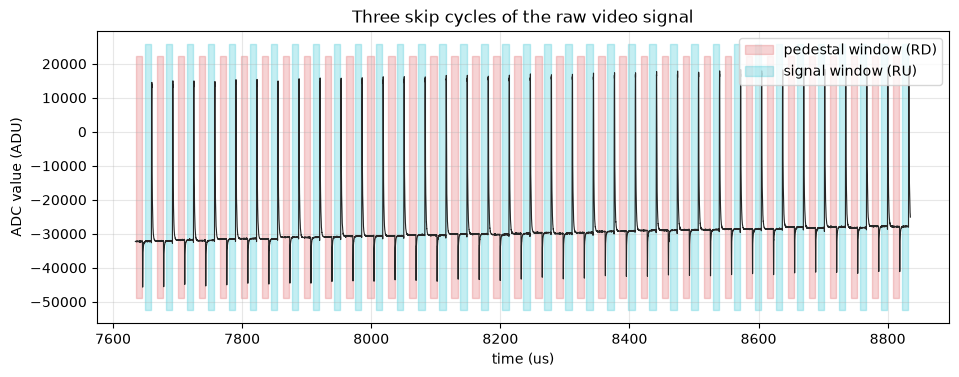

In [3]:
# Look at a few skip cycles: the signal with the pedestal (red) and signal (cyan) windows shaded
start = int(A.window_slices()[0][5000 // 489])          # a window start somewhere in the first pixel
i0, i1 = start - 10, start + 3 * 6000
t = np.arange(i0, i1) / US
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(t, A.values[i0:i1], color="0.15", lw=0.8)
ax.fill_between(t, *ax.get_ylim(), where=A.rd[i0:i1], color="tab:red", alpha=0.2, label="pedestal window (RD)")
ax.fill_between(t, *ax.get_ylim(), where=A.ru[i0:i1], color="tab:cyan", alpha=0.25, label="signal window (RU)")
ax.set(xlabel="time (us)", ylabel="ADC value (ADU)", title="Three skip cycles of the raw video signal")
ax.legend(loc="upper right")
plt.show()

**What to look for.** Each cycle is: pedestal window → a short dip → signal window → a big pulse and a decaying tail. Every skip
repeats the same sequence, which is why we can stack the repeats later. Each window is 150 samples (10 µs).
The skip CDS (pedestal minus signal) measures the charge in the pixel.

## Step 2. Cut the trace into regions

A readout alternates between three kinds of segments:

| Region | What happens | Repeats |
|---|---|---|
| vertical transfers | charge moves one row | once per row |
| horizontal transfers | charge moves along the serial register | before every pixel |
| skip region | the pixel is read `NDCM` times | 500 skip cycles |

`split_regions` finds the boundaries from the window flags and the transfer flags, and returns every repeat as its own row.

It works for any trace geometry and timing:

* pixels come from the order of the windows;
* the cycle comes from the spacing of the pedestal windows;
* horizontal transfers come from flag bit 6 and vertical transfers from bit 7;
* row starts come from `NCOL` in the `.meta` if it is given (`split_regions(trace, meta)`), otherwise
  from the vertical transfers.

Here it is called without the `.meta`, so the layout is found from the data alone.

In [4]:
rA = tr.split_regions(A)
print(f"pixels                : {rA.n_pixels}")
print(f"skip cycle            : {rA.period} samples = {rA.period/US:.1f} us; pedestal window {rA.n_ped} samples")
print(f"skip cycles per pixel : {[len(x) for x in rA.skip]}")
print(f"horizontal transfers  : {rA.h[0].shape} per pixel (n_transfers, samples)")
print(f"vertical transfers    : {None if rA.v is None else rA.v.shape} (n_transfers, samples)")

pixels                : 10
skip cycle            : 489 samples = 32.6 us; pedestal window 150 samples
skip cycles per pixel : [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]
horizontal transfers  : (19, 1894) per pixel (n_transfers, samples)
vertical transfers    : (18, 5404) (n_transfers, samples)


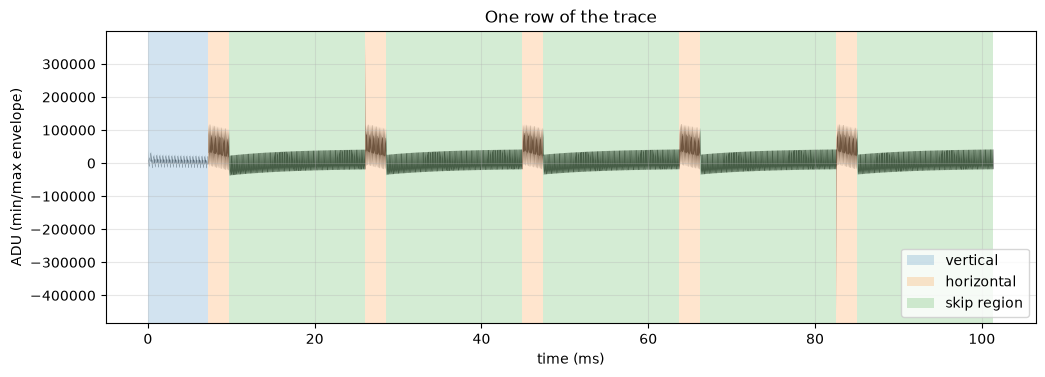

In [5]:
# Overview of one row: vertical block, then horizontal block + skip region of every pixel
values = A.values.astype(float)
v_lo, v_hi = rA.v_bounds
first_pixel = next(k for k, (s, _) in enumerate(rA.skip_bounds) if s >= v_hi)
lo, hi = v_lo, rA.skip_bounds[-1][1]
chunk = 400
seg = values[lo:hi]; n = len(seg) // chunk
blocks = seg[:n * chunk].reshape(n, chunk)
t_ms = (np.arange(n) * chunk + chunk / 2) / US / 1000
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.fill_between(t_ms, blocks.min(1), blocks.max(1), color="0.3", lw=0)
span = lambda a, b, c, l: ax.axvspan((a - lo) / US / 1000, (b - lo) / US / 1000, color=c, alpha=0.2, lw=0, label=l)
span(v_lo, v_hi, "tab:blue", "vertical")
for k in range(first_pixel, rA.n_pixels):
    s, e = rA.skip_bounds[k]
    span(s - rA.h_block, s, "tab:orange", "horizontal" if k == first_pixel else None)
    span(s, e, "tab:green", "skip region" if k == first_pixel else None)
ax.set(xlabel="time (ms)", ylabel="ADU (min/max envelope)", title="One row of the trace")
ax.legend(loc="lower right"); plt.show()

**What to look for.** The skip regions (green) are long; the horizontal blocks (orange) are short and large in amplitude; the first block of a row is the
vertical transfer (blue). The baseline *rises* across each skip region: that is the reset-leakage droop.

## Step 3. One pixel: baseline, template and CDS

For one pixel we have 500 skip cycles, `rA.skip[pixel]` with shape `(500, 489)`. Three ideas:

* **baseline** $b_k$: the mean of the pedestal window of skip $k$. It drifts (droop), so we subtract it from each cycle;
* **template** $m_j$: the mean of the baseline-removed cycles (skips 5 onwards). It is the typical shape of the cycle;
* **CDS** $c_k$: pedestal minus signal for skip $k$ (the charge signal), from the inline records.

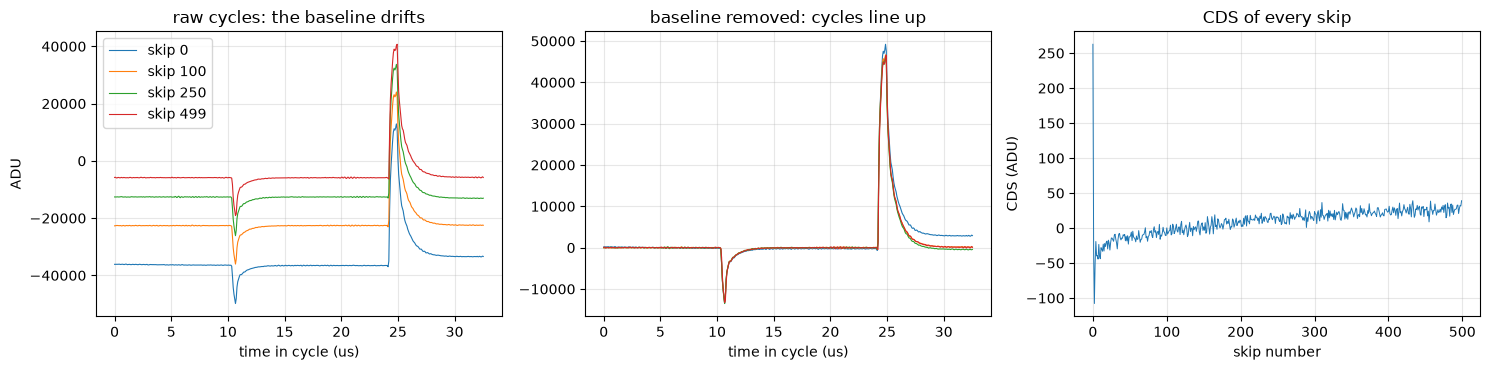

In [6]:
PIXEL = 0
cycles = rA.skip[PIXEL].astype(float)                       # (500, 489)
baseline = cycles[:, :rA.n_ped].mean(axis=1)                # b_k
shape = cycles - baseline[:, None]                          # baseline removed
template = shape[5:].mean(axis=0)                           # m_j
cds = rA.cds[PIXEL]                                         # c_k
t = np.arange(rA.period) / US

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for k in (0, 100, 250, 499):
    ax[0].plot(t, cycles[k], lw=0.8, label=f"skip {k}")
ax[0].set(title="raw cycles: the baseline drifts", xlabel="time in cycle (us)", ylabel="ADU"); ax[0].legend()
for k in (0, 100, 250, 499):
    ax[1].plot(t, shape[k], lw=0.8)
ax[1].set(title="baseline removed: cycles line up", xlabel="time in cycle (us)")
ax[2].plot(np.arange(len(cds)), cds, lw=0.7)
ax[2].set(title="CDS of every skip", xlabel="skip number", ylabel="CDS (ADU)")
plt.tight_layout(); plt.show()

**What to look for.** Left: the raw cycles sit at very different heights (the droop). Middle: after subtracting each cycle's baseline they
overlap almost perfectly, so the *shape* of the cycle is very reproducible. Right: the CDS is small and noisy, but the first few skips
are different (a transient); we exclude skips 0–4 from the template for that reason.

## Step 4. The simple measurements (summary tools)

`skip_tools(regions, pixel)` returns every measurement for one pixel. The scalar ones read a number off the template, the baseline, or the CDS.
Here they are, marked on the data.

In [7]:
tools = ct.skip_tools(rA, PIXEL)
scalars = {k: v for k, v in tools.items() if np.ndim(v) == 0 and not k.startswith("fit")}
for name, value in scalars.items():
    print(f"{name:42s} {value:12.3f}")

skip: dip height                             -13392.826
skip: signal-window level                        -2.692
skip: pulse peak height                       46465.578
skip: end-of-cycle tail level                    72.352
skip: baseline at skip 1                     -33378.573
skip: droop total                             27517.713
skip: droop half-time (skips)                   130.000
skip: CDS mean (skips>=10)                       10.194
skip: CDS rms (detrended)                         5.629
skip: first-skip CDS excess                     248.640
skip: skips 1-4 CDS ringing                      74.701
skip: CDS autocorrelation at lag 2               -0.137
skip: noise of 10-skip average                    1.487
skip: noise of 50-skip average                    0.619
skip: noise power 0.1-1 MHz                       3.869
skip: noise power 1-3 MHz                         4.661
skip: noise power 3-7.5 MHz                       5.310


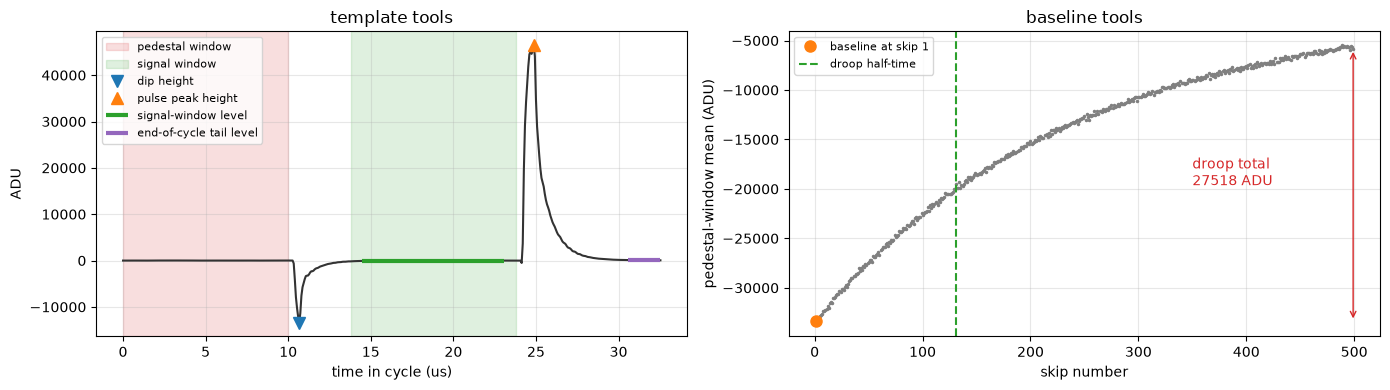

In [8]:
n_ped, j_sig = rA.n_ped, rA.sig_start
i_dip = n_ped + int(np.argmin(template[n_ped:j_sig]))
i_peak = j_sig + n_ped + int(np.argmax(template[j_sig + n_ped:]))
sig = slice(j_sig + 10, j_sig + n_ped - 10)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
a = ax[0]
a.plot(t, template, color="0.2")
a.axvspan(0, n_ped / US, color="tab:red", alpha=0.15, label="pedestal window")
a.axvspan(j_sig / US, (j_sig + n_ped) / US, color="tab:green", alpha=0.15, label="signal window")
a.plot(i_dip / US, template[i_dip], "v", ms=9, color="tab:blue", label="dip height")
a.plot(i_peak / US, template[i_peak], "^", ms=9, color="tab:orange", label="pulse peak height")
a.hlines(template[sig].mean(), t[sig][0], t[sig][-1], color="tab:green", lw=3, label="signal-window level")
a.hlines(template[-30:].mean(), t[-30], t[-1], color="tab:purple", lw=3, label="end-of-cycle tail level")
a.set(title="template tools", xlabel="time in cycle (us)", ylabel="ADU"); a.legend(fontsize=8)

a = ax[1]
a.plot(np.arange(1, len(baseline)), baseline[1:], ".", ms=3, color="0.5")
a.plot(1, baseline[1], "o", color="tab:orange", ms=8, label="baseline at skip 1")
total = baseline[-1] - baseline[1]
a.annotate("", xy=(len(baseline) - 1, baseline[-1]), xytext=(len(baseline) - 1, baseline[1]), arrowprops=dict(arrowstyle="<->", color="tab:red"))
a.text(len(baseline) * 0.7, (baseline[1] + baseline[-1]) / 2, f"droop total\n{total:.0f} ADU", color="tab:red")
a.axvline(tools["skip: droop half-time (skips)"] + 1, color="tab:green", ls="--", label="droop half-time")
a.set(title="baseline tools", xlabel="skip number", ylabel="pedestal-window mean (ADU)"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**What to look for.** Every tool is a number with a clear meaning:

* *dip height, pulse peak height, signal-window level, tail level*: the size of different parts of the cycle (they scale with clock swings and amplifier gain);
* *baseline at skip 1, droop total, droop half-time*: the leakage droop;
* *CDS mean, CDS rms, first-skip excess, skips 1–4 ringing, lag-2 autocorrelation*: properties of the CDS series (charge level, noise, transient, correlation between skips);
* *noise of 10- and 50-skip average, noise power in three bands*: how noise behaves when averaged and across frequency.

## Step 5. The fitted measurements (fit tools)

A fit tool fits a small physical model and reports its **parameters** (time constants and amplitudes). They need no new data: they are
extracted from the same template, baseline and CDS.

1. **Exponential** $y = c + A e^{-x/\tau}$ on three curves: the recovery after the dip, the settling after the pulse, and the baseline droop.
   `fit_exponential` tries many $\tau$, solving $A$ and $c$ exactly by least squares each time.
2. **Damped ringing** of the first 20 CDS values: $y_k = e^{-k/\tau}(a\cos 2\pi fk + b\sin 2\pi fk)$.
3. **Noise model** $\sigma(N)^2 = \sigma_w^2/N + \sigma_f^2$: white noise per skip and a floor that averaging cannot remove.

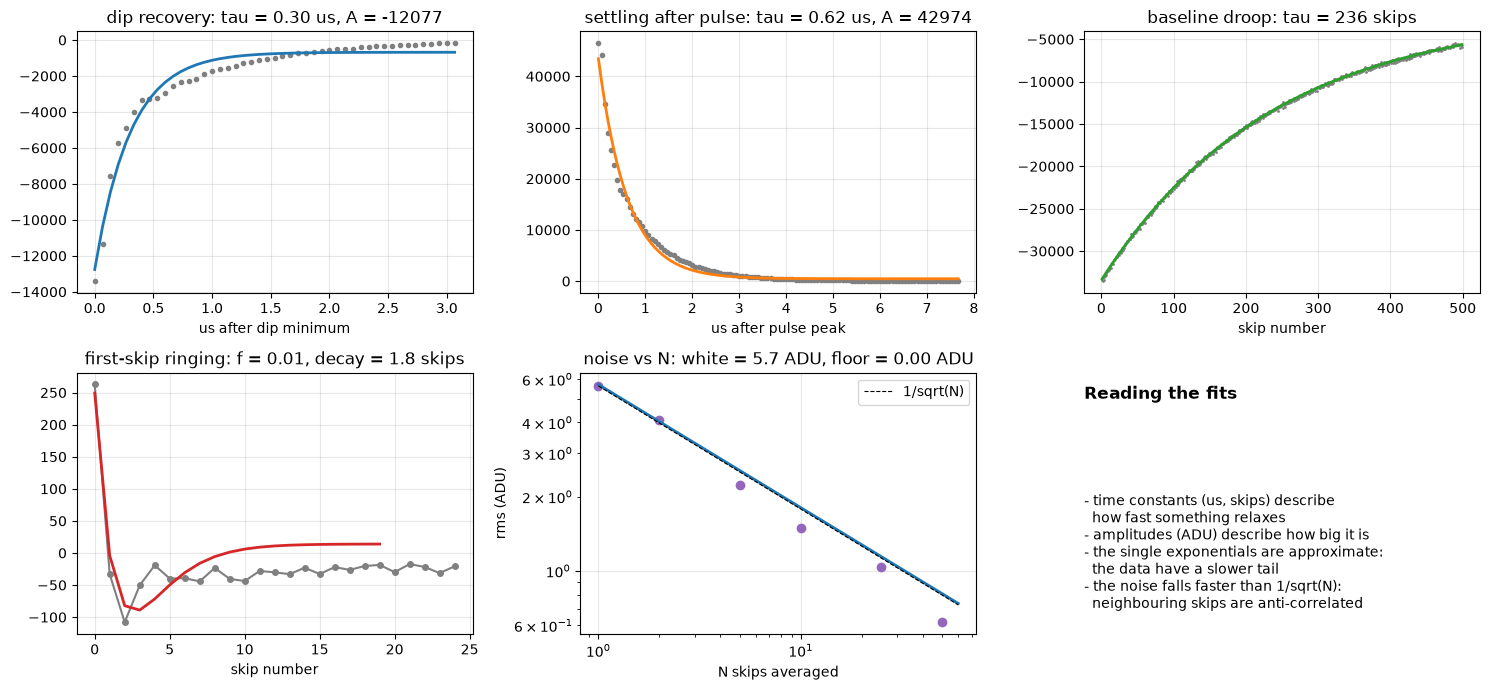

In [9]:
later = cds[10:]
# 1. exponentials
tau_dip, A_dip, c_dip = ct.fit_exponential(np.arange(j_sig - i_dip) / US, template[i_dip:j_sig], 0.02, 10)
tau_set, A_set, c_set = ct.fit_exponential(np.arange(len(template) - i_peak) / US, template[i_peak:], 0.05, 20)
k = np.arange(1, len(baseline)).astype(float)
tau_dr, A_dr, c_dr = ct.fit_exponential(k, baseline[1:], 5, 5000)
# 2. ringing
freq, tau_ring, amp_ring = ct.fit_damped_ringing(cds[:20] - np.median(later))
# 3. noise model
sizes = [1, 2, 5, 10, 25, 50]
resid = ct._poly_detrended(later)
noise = [resid[:len(resid) // n * n].reshape(-1, n).mean(axis=1).std(ddof=1) for n in sizes]
white, floor = ct.fit_noise_model(sizes, noise)

fig, ax = plt.subplots(2, 3, figsize=(15, 7))
x = np.arange(j_sig - i_dip) / US
ax[0, 0].plot(x, template[i_dip:j_sig], ".", color="0.5"); ax[0, 0].plot(x, c_dip + A_dip * np.exp(-x / tau_dip), lw=2)
ax[0, 0].set(title=f"dip recovery: tau = {tau_dip:.2f} us, A = {A_dip:.0f}", xlabel="us after dip minimum")
x = np.arange(len(template) - i_peak) / US
ax[0, 1].plot(x, template[i_peak:], ".", color="0.5"); ax[0, 1].plot(x, c_set + A_set * np.exp(-x / tau_set), lw=2, color="tab:orange")
ax[0, 1].set(title=f"settling after pulse: tau = {tau_set:.2f} us, A = {A_set:.0f}", xlabel="us after pulse peak")
ax[0, 2].plot(k, baseline[1:], ".", ms=2, color="0.5"); ax[0, 2].plot(k, c_dr + A_dr * np.exp(-k / tau_dr), lw=2, color="tab:green")
ax[0, 2].set(title=f"baseline droop: tau = {tau_dr:.0f} skips", xlabel="skip number")
kk = np.arange(20); env = np.exp(-kk / tau_ring)
B = np.column_stack([env * np.cos(2 * np.pi * freq * kk), env * np.sin(2 * np.pi * freq * kk)])
coef = np.linalg.lstsq(B, cds[:20] - np.median(later), rcond=None)[0]
ax[1, 0].plot(np.arange(25), cds[:25], "o-", ms=4, color="0.5"); ax[1, 0].plot(kk, np.median(later) + B @ coef, lw=2, color="tab:red")
ax[1, 0].set(title=f"first-skip ringing: f = {freq:.2f}, decay = {tau_ring:.1f} skips", xlabel="skip number")
grid = np.geomspace(1, 60, 100)
ax[1, 1].loglog(sizes, noise, "o", color="tab:purple"); ax[1, 1].loglog(grid, np.sqrt(white**2 / grid + floor**2), lw=2)
ax[1, 1].loglog(grid, noise[0] / np.sqrt(grid), "k--", lw=0.8, label="1/sqrt(N)"); ax[1, 1].legend()
ax[1, 1].set(title=f"noise vs N: white = {white:.1f} ADU, floor = {floor:.2f} ADU", xlabel="N skips averaged", ylabel="rms (ADU)")
ax[1, 2].axis("off")
ax[1, 2].text(0, 0.9, "Reading the fits", fontsize=12, weight="bold")
ax[1, 2].text(0, 0.1, "- time constants (us, skips) describe\n  how fast something relaxes\n- amplitudes (ADU) describe how big it is\n- the single exponentials are approximate:\n  the data have a slower tail\n- the noise falls faster than 1/sqrt(N):\n  neighbouring skips are anti-correlated", fontsize=10)
plt.tight_layout(); plt.show()

**What to look for.** The curves follow the data in outline but not perfectly (a single exponential is a simplification), so treat the fitted numbers as
*descriptive parameters* to compare between traces, not as circuit values. In the noise panel the points fall *below* the $1/\sqrt{N}$ line: averaging helps more than for white noise,
because nearby CDS values are anti-correlated. A pure white-plus-floor model cannot describe that, so its floor is small.

## Step 6. Replicates: one trace gives ten pixels

To ask whether a difference is real, we need to know how much a tool varies when nothing changes. We use the **pixels as replicates**:
`measure` evaluates every tool on every pixel, so each tool becomes an array with one row per pixel.

But not all pixels are alike. The first pixel of each row (pixel 0 and pixel 5 here) is read right after the vertical transfers and behaves differently;
a pixel that contains a large charge distorts the waveform tools. `usable_pixels` removes both kinds.

row-start pixels : [0, 5]
usable pixels    : [1, 2, 3, 4, 6, 7, 8, 9]


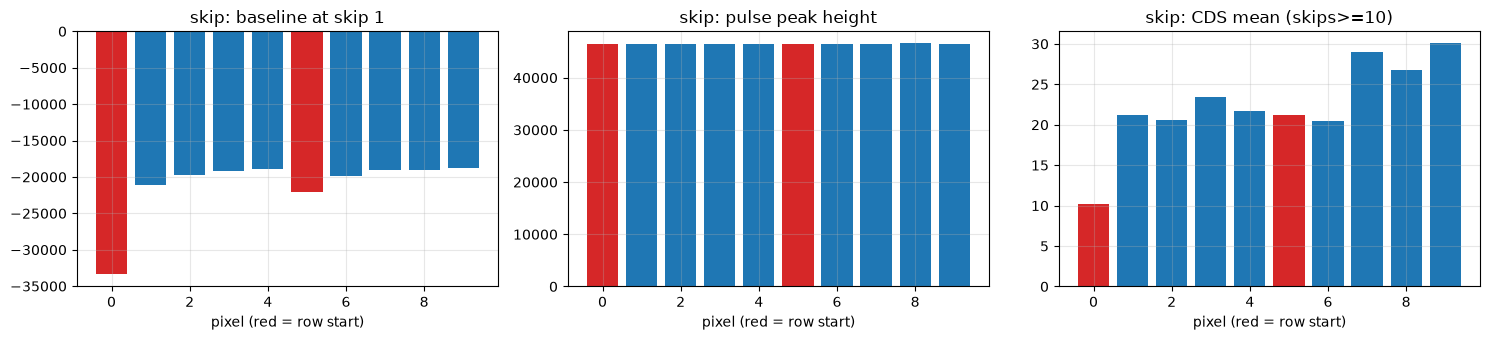

In [10]:
print("row-start pixels :", ct.row_start_pixels(rA))
print("usable pixels    :", ct.usable_pixels(rA))
measA_all = ct.measure(rA)                       # all 10 pixels
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, name in zip(ax, ["skip: baseline at skip 1", "skip: pulse peak height", "skip: CDS mean (skips>=10)"]):
    vals = measA_all.tools[name]
    colors = ["tab:red" if p in ct.row_start_pixels(rA) else "tab:blue" for p in range(len(vals))]
    a.bar(range(len(vals)), vals, color=colors); a.set(title=name, xlabel="pixel (red = row start)")
plt.tight_layout(); plt.show()

**What to look for.** The red bars (row-start pixels) stand out in the baseline. Since one bad pixel can create a false "difference", the
comparison below uses only the usable pixels.

## Step 7. Compare trace A with trace B

Now the main event. For every tool we have 8 values for A and 8 for B (one per usable pixel). `run_tests` asks, for each tool:
*is the difference between the A values and the B values larger than the pixel-to-pixel scatter?* It returns a $z$ (the difference in
units of its error) and a permutation $p$-value.

In [11]:
B_dec = dt.decode_trace(TRACE_B)
print("B quality problems:", B_dec.quality_problems() or "none")
rB = tr.split_regions(B_dec)
measA = ct.measure(rA, ct.usable_pixels(rA))
measB = ct.measure(rB, ct.usable_pixels(rB))

N_PERM = 10000                              # random relabelings per tool; sets the smallest possible p-value
results = [r for r in ct.run_tests(measA.tools, measB.tools, N_PERM, seed=0) if ct.in_verdict(r)]
threshold = 0.01 / len(results)               # Bonferroni: 1% overall false-alarm rate across all tools
ranked = sorted(results, key=lambda r: (r["p"], -r["z"]))
print(f"{len(results)} tools tested; a tool 'distinguishes' the traces if p < {threshold:.2g}")
n_a, n_b = len(ct.usable_pixels(rA)), len(ct.usable_pixels(rB))
p_floor = ct.smallest_possible_p(n_a, n_b, N_PERM)
print(f"{n_a} + {n_b} pixels -> {ct.n_labelings(n_a, n_b):,} distinct labelings; smallest p this test can report: {p_floor:.1e}")
print("(this must be below the threshold, otherwise nothing could ever be flagged; with few pixels ALL labelings are enumerated, so the p-values are exact)\n")
print(f"{'tool':46s} {'z':>8s} {'p':>9s}  verdict")
for r in ranked:
    verdict = "DISTINGUISHES" if r["p"] < threshold else ("marginal" if r["p"] < 0.05 else "-")
    print(f"{r['tool']:46s} {r['z']:8.1f} {r['p']:9.2g}  {verdict}")

B quality problems: none


35 tools tested; a tool 'distinguishes' the traces if p < 0.00029
8 + 8 pixels -> 12,870 distinct labelings; smallest p this test can report: 1.6e-04
(this must be below the threshold, otherwise nothing could ever be flagged; with few pixels ALL labelings are enumerated, so the p-values are exact)

tool                                                  z         p  verdict
skip: dip height                                  595.2   0.00016  DISTINGUISHES
skip: pulse peak height                           402.8   0.00016  DISTINGUISHES
fit: dip recovery time (us)                       199.6   0.00016  DISTINGUISHES
fit: dip recovery amplitude                       186.1   0.00016  DISTINGUISHES
fit: settling time after pulse (us)               162.8   0.00016  DISTINGUISHES
fit: settling amplitude after pulse               133.1   0.00016  DISTINGUISHES
skip: mean shape                                  122.4   0.00016  DISTINGUISHES
skip: noise power 1-3 MHz                          99.1   

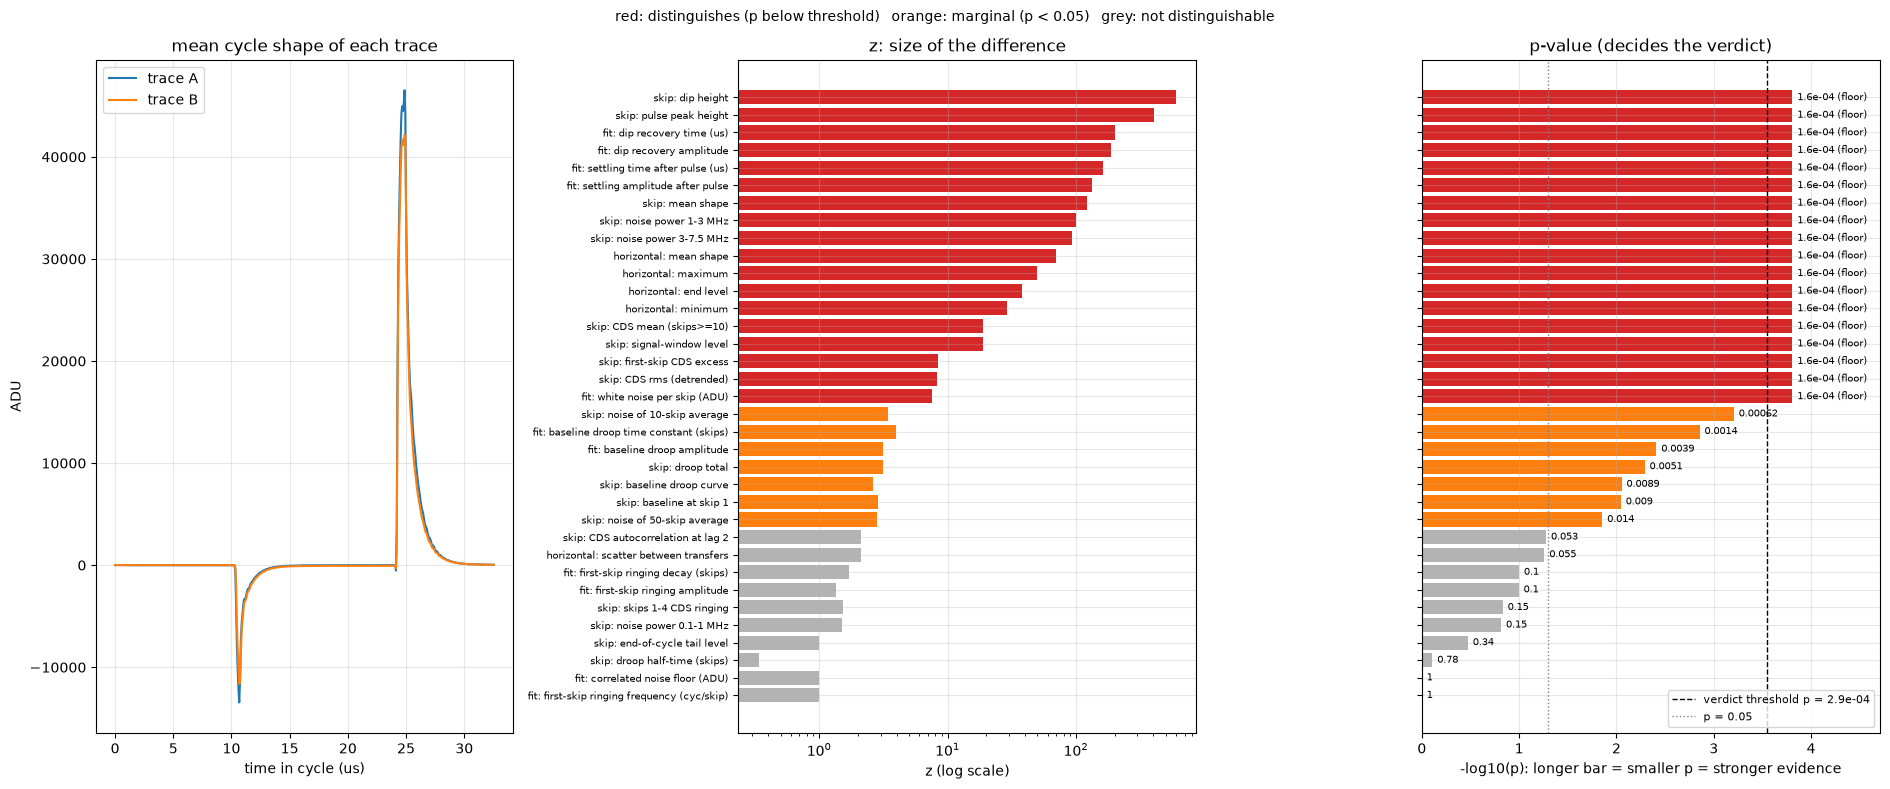

In [12]:
# the two mean shapes and the tools, as pictures
def run_template(r):
    pix = ct.usable_pixels(r)
    out = []
    for p in pix:
        c = r.skip[p].astype(float); c -= c[:, :r.n_ped].mean(axis=1, keepdims=True); out.append(c[5:].mean(axis=0))
    return np.mean(out, axis=0)
tA, tB = run_template(rA), run_template(rB)
names = [r["tool"] for r in ranked]                       # already sorted by p-value
zs = np.array([max(r["z"], 0.01) for r in ranked])
ps = np.array([r["p"] for r in ranked])
colors = ["tab:red" if r["p"] < threshold else ("tab:orange" if r["p"] < 0.05 else "0.7") for r in ranked]
ypos = np.arange(len(names))[::-1]

fig, ax = plt.subplots(1, 3, figsize=(19, 8), gridspec_kw={"width_ratios": [1.0, 1.1, 1.1]})
ax[0].plot(t, tA, label="trace A"); ax[0].plot(t, tB, label="trace B")
ax[0].set(title="mean cycle shape of each trace", xlabel="time in cycle (us)", ylabel="ADU"); ax[0].legend()

# z: how big is the difference (in units of its error)
ax[1].barh(ypos, zs, color=colors); ax[1].set_yticks(ypos); ax[1].set_yticklabels(names, fontsize=7)
ax[1].set_xscale("log"); ax[1].set(title="z: size of the difference", xlabel="z (log scale)")

# p: is it more than chance?  -log10(p): longer bar = smaller p = stronger evidence
score = -np.log10(np.maximum(ps, p_floor))
ax[2].barh(ypos, score, color=colors)
ax[2].axvline(-np.log10(threshold), color="k", ls="--", lw=1, label=f"verdict threshold p = {threshold:.1e}")
ax[2].axvline(-np.log10(0.05), color="0.5", ls=":", lw=1, label="p = 0.05")
for y, pv, sc in zip(ypos, ps, score):
    ax[2].text(sc + 0.05, y, f"{pv:.1e} (floor)" if pv <= p_floor * 1.01 else f"{pv:.2g}", va="center", fontsize=7)
ax[2].set_yticks(ypos); ax[2].set_yticklabels([]); ax[2].set_xlim(0, -np.log10(p_floor) + 0.9)
ax[2].set(title="p-value (decides the verdict)", xlabel="-log10(p): longer bar = smaller p = stronger evidence"); ax[2].legend(fontsize=8, loc="lower right")
fig.suptitle("red: distinguishes (p below threshold)   orange: marginal (p < 0.05)   grey: not distinguishable", fontsize=10)
plt.tight_layout(); plt.show()

**What to look for.** The colors follow the **p-value panel** (right): a bar past the dashed line is red. The z panel (middle) says *how big* the difference is, the p panel says *whether it is more than chance*; many tools sit at the same smallest possible p (marked "floor"): with only 8 + 8 pixels there are 12,870 labelings, so no p can go lower, and the tools tied at the floor are ranked by z instead. The traces differ at the edges (dip, pulse) and in the tails, so the edge heights, the exponential amplitudes and the noise-power bands are near the top. Tools such as the
baseline droop and tail level are near the bottom: they do not tell these two amplifiers apart. *This ranking is the answer to "which tools tell the traces apart best".*

## Step 8. How the permutation test works

For one tool, suppose A has values $a_1\dots a_8$ and B has $b_1\dots b_8$. If the traces were really the same, it would not matter which values carry
the label "A" and which "B". So we **shuffle the labels** many times, compute the difference each time, and see how often a shuffled difference is
as large as the real one. That fraction is the $p$-value. Nothing is assumed about the shape of the distribution.

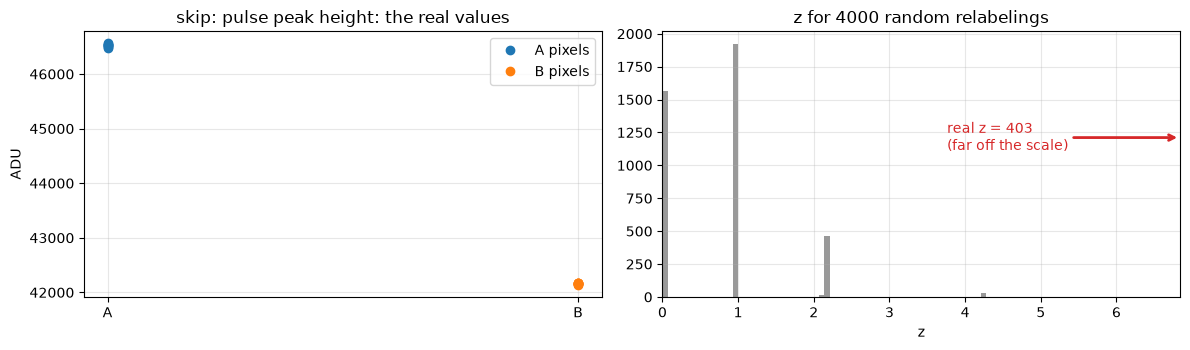

fraction of shuffles with z >= real z: 0.0000  (0 means p < 1/4000)


In [13]:
TOOL = "skip: pulse peak height"
a, b = measA.tools[TOOL], measB.tools[TOOL]
x = np.concatenate([a, b]).astype(float).reshape(len(a) + len(b), -1)
rng = np.random.default_rng(0)
labelings = np.zeros((4000, len(x)))
for i in range(len(labelings)):
    labelings[i, rng.permutation(len(x))[:len(a)]] = 1
z_shuffled = ct._welch_statistic(x, labelings)
z_real = ct._welch_statistic(x, np.r_[np.ones(len(a)), np.zeros(len(b))][None, :])[0]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(np.zeros(len(a)), a, "o", label="A pixels"); ax[0].plot(np.ones(len(b)), b, "o", label="B pixels")
ax[0].set(xticks=[0, 1], xticklabels=["A", "B"], title=f"{TOOL}: the real values", ylabel="ADU"); ax[0].legend()
ax[1].hist(z_shuffled, bins=60, color="0.6")
right = max(z_shuffled.max() * 1.6, 1)
ax[1].set_xlim(0, right)
if z_real <= right:
    ax[1].axvline(z_real, color="tab:red", lw=2, label=f"real z = {z_real:.1f}")
else:                                              # the real value is far off the scale of the shuffles
    ax[1].annotate(f"real z = {z_real:.0f}\n(far off the scale)", xy=(right, ax[1].get_ylim()[1] * 0.6),
                   xytext=(right * 0.55, ax[1].get_ylim()[1] * 0.6), color="tab:red", va="center",
                   arrowprops=dict(arrowstyle="->", color="tab:red", lw=2))
ax[1].set(title="z for 4000 random relabelings", xlabel="z")
plt.tight_layout(); plt.show()
print(f"fraction of shuffles with z >= real z: {(z_shuffled >= z_real).mean():.4f}  (0 means p < 1/4000)")

**What to look for.** The red line (real labeling) is far to the right of everything the shuffles produce: a difference this large is not something random labeling can create.

## Step 9. Controls: does the method say "same" when it should?

A tool that says "different" for everything is useless. So we run the *same test on trace A alone*, split in two:

* **even vs odd** pixels,
* **first half vs second half** (row 1 vs row 2).

Both should come out "not distinguishable". If a tool fires in a control, the verdict is declared inconclusive.

In [14]:
controls = {
    "even vs odd pixels": ct.run_tests(*ct.split_even_odd(measA.tools), n_perm=N_PERM, seed=1),
    "first vs second half": ct.run_tests(*ct.split_halves(measA.tools), n_perm=N_PERM, seed=2),
}
for label, res in controls.items():
    res = [r for r in res if ct.in_verdict(r)]
    below05 = [r for r in res if r["p"] < 0.05]
    bonf = [r for r in res if r["p"] < 0.01 / len(res)]
    print(f"{label:24s}: {len(below05)} of {len(res)} tools below p=0.05 (about {0.05*len(res):.1f} by chance);"
          f" {len(bonf)} below the corrected threshold; smallest p = {min(r['p'] for r in res):.3g}"
          f" -> {'PASSED' if not bonf else 'FAILED'}")

even vs odd pixels      : 3 of 35 tools below p=0.05 (about 1.8 by chance); 0 below the corrected threshold; smallest p = 0.0286 -> PASSED
first vs second half    : 1 of 35 tools below p=0.05 (about 1.8 by chance); 0 below the corrected threshold; smallest p = 0.0286 -> PASSED


**What to look for.** A few tools may dip below 0.05 purely by chance (about 5%), but none should pass the corrected threshold. Compare this with Step 7, where many tools had $p$ around $10^{-4}$.
The gap between the control and the real comparison is what makes the verdict meaningful.

## Step 10. The full verdict in one call

`report` prints everything together: timing check, ranked results, summary by region, both controls, and the verdict.
This is what `python src/compare_trace.py A B` prints.

In [15]:
controls_full = {"into even/odd replicates": controls["even vs odd pixels"],
                 "into first/second half (row 1 / row 2)": controls["first vs second half"]}
all_results = ct.run_tests(measA.tools, measB.tools, N_PERM, seed=0)         # includes the information-only vertical tools
distinguishable = ct.report(TRACE_A.name, TRACE_B.name, all_results, controls_full, measA.timing, measB.timing, 0.01, N_PERM)
print("\nreturned:", distinguishable)


A = trace_2x5x500_20x20_ch0_101_20261008_185447_12.RJ45ADCDATA0
B = trace_2x5x500_20x20_ch3_101_20261008_185450_15.RJ45ADCDATA3
35 tools used for the verdict (+4 informational); a tool distinguishes the traces if p < 0.00029 (Bonferroni, alpha = 0.01)

smallest p this test can report: 0.00016 (12,870 distinct labelings of 8 + 8 replicates)

TIMING (exact, no statistics)
  skip cycle (samples)               A=   489.00  B=   489.00  same
  horizontal transfer (samples)      A=  1894.00  B=  1894.00  same
  vertical transfer (samples)        A=  5404.00  B=  5404.00  same

RESULTS (ranked)
  tool                                                   z         p  verdict   (* = at the smallest p the test can report)
  vertical: minimum                                  17.84  1.0e-04*  (information only)
  vertical: mean shape                               11.67  1.0e-04*  (information only)
  vertical: maximum                                   8.78  1.0e-04*  (information only)
  skip: dip h

## Step 11. Going further: do real repeats pass the test?

The strongest test of the method is to compare traces that **should** look the same: repeats of one amplifier with identical parameters.
The session folder has several. We compare every pair of healthy channel-0 repeats, and also ask how large the A-vs-B difference is in units of the
*run-to-run* spread, which is the honest noise floor.

In [16]:
# 1. all healthy channel-0 repeats, measured on their usable pixels
files = sorted(glob.glob(str(SESSION / "trace_*_ch0_101_*.RJ45ADCDATA0")))
repeats = []
for f in files:
    d = dt.decode_trace(f)
    if d.quality_problems():
        print("skipping damaged trace:", Path(f).name[-30:])
        continue
    r = tr.split_regions(d)
    repeats.append(ct.measure(r, ct.usable_pixels(r)))
print(f"{len(repeats)} healthy channel-0 repeats")

# 2. the same test on every PAIR of repeats (identical parameters: the answer should be 'same')
pair_results = []
for i, j in itertools.combinations(range(len(repeats)), 2):
    res = [r for r in ct.run_tests(repeats[i].tools, repeats[j].tools, N_PERM, seed=10 * i + j) if ct.in_verdict(r)]
    pair_results.append({r["tool"]: r for r in res})
ab = {r["tool"]: r for r in ranked}                                    # A vs B from Step 7

flags_repeats = [sum(d[t]["p"] < threshold for t in d) for d in pair_results]
flags_ab = sum(r["p"] < threshold for r in ranked)
print(f"tools flagged per pair of repeats (identical parameters): {flags_repeats} of {len(ranked)}")
print(f"tools flagged for A vs B                                : {flags_ab} of {len(ranked)}")

false_alarm = [t for t in ab if any(d[t]["p"] < threshold for d in pair_results)]
trustworthy = [t for t in ab if ab[t]["p"] < threshold and t not in false_alarm]
print("\nFlagged for A vs B and NEVER flagged on a pair of repeats (the trustworthy tools):")
for t in trustworthy: print("   ", t)
print("\nFlagged for A vs B but ALSO on at least one pair of repeats (false-alarm prone):")
for t in false_alarm:
    if ab[t]["p"] < threshold:
        print(f"    {t:44s} fires on {sum(d[t]['p'] < threshold for d in pair_results)} of {len(pair_results)} repeat pairs")

skipping damaged trace: 0261008_185455_20.RJ45ADCDATA0


4 healthy channel-0 repeats


tools flagged per pair of repeats (identical parameters): [6, 8, 0, 6, 6, 8] of 35
tools flagged for A vs B                                : 18 of 35

Flagged for A vs B and NEVER flagged on a pair of repeats (the trustworthy tools):
    fit: settling time after pulse (us)
    skip: noise power 1-3 MHz
    skip: noise power 3-7.5 MHz
    horizontal: mean shape
    horizontal: maximum
    horizontal: end level
    horizontal: minimum
    skip: first-skip CDS excess
    skip: CDS rms (detrended)
    fit: white noise per skip (ADU)

Flagged for A vs B but ALSO on at least one pair of repeats (false-alarm prone):
    skip: dip height                             fires on 3 of 6 repeat pairs
    skip: pulse peak height                      fires on 4 of 6 repeat pairs
    fit: dip recovery time (us)                  fires on 3 of 6 repeat pairs
    fit: dip recovery amplitude                  fires on 5 of 6 repeat pairs
    fit: settling amplitude after pulse          fires on 4 of 6 repeat

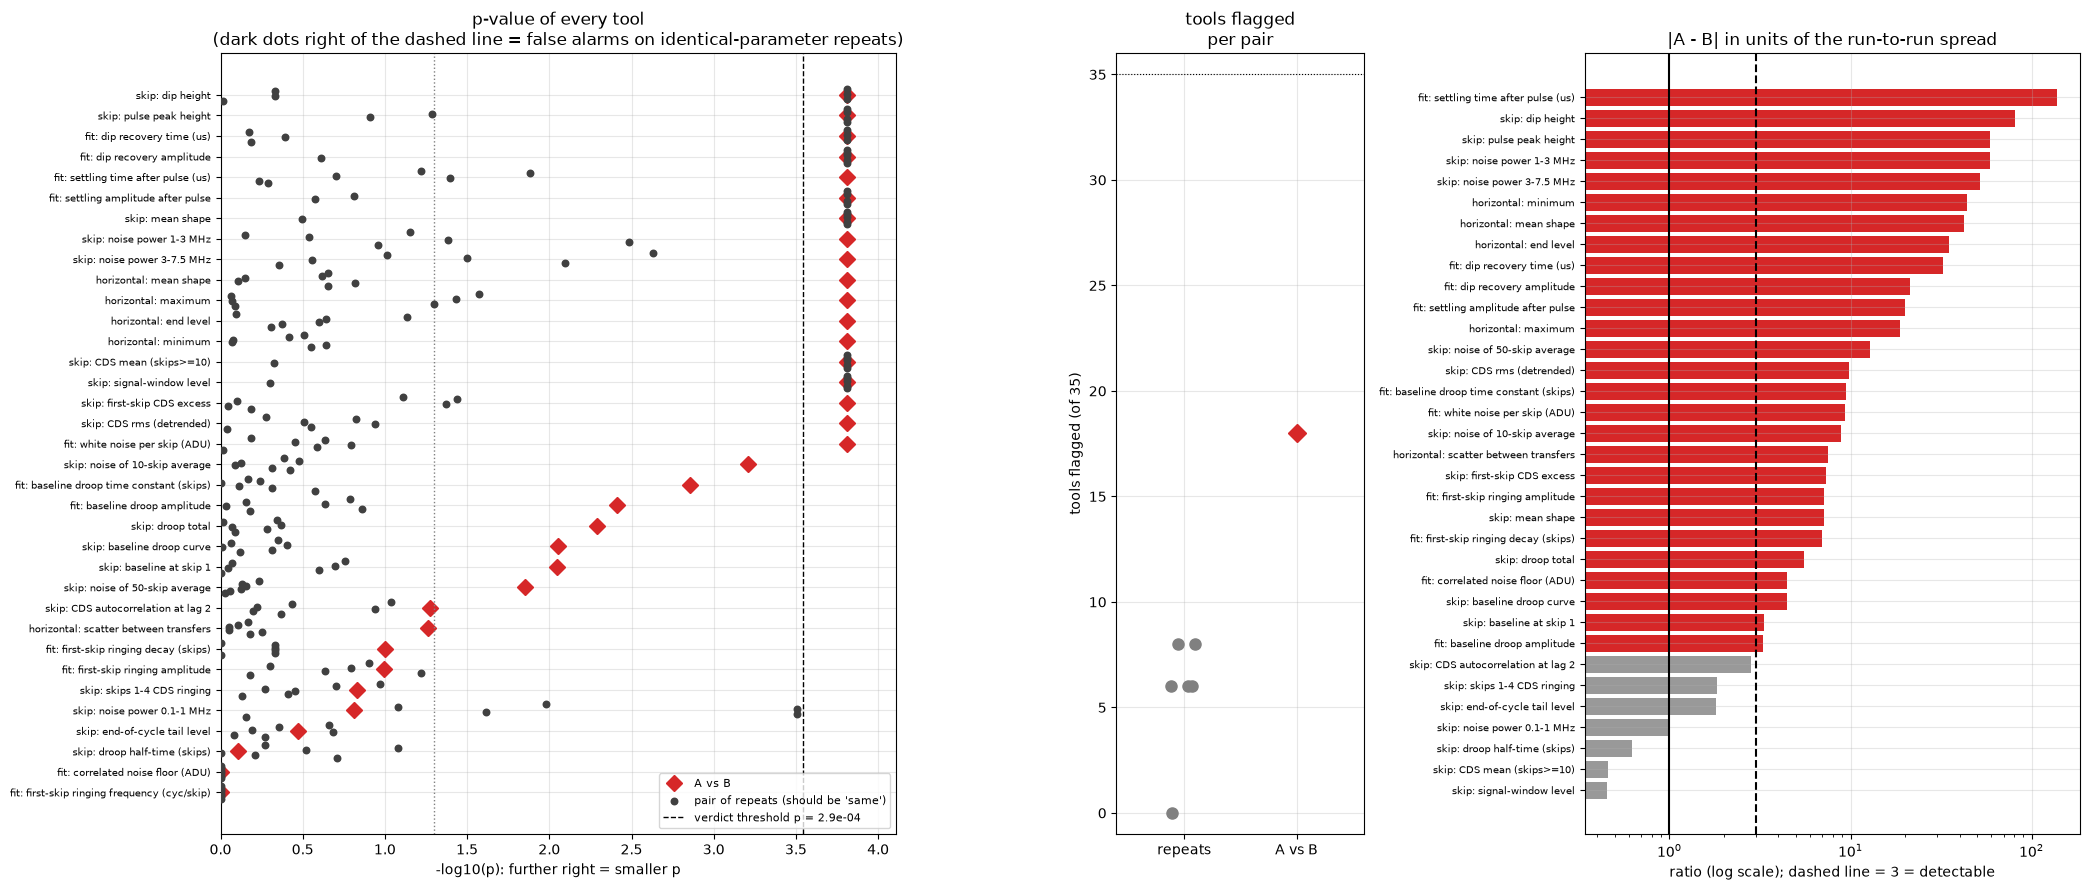

In [17]:
# 3. the picture: p-value of every tool, for every repeat pair (grey) and for A vs B (red)
order = [r["tool"] for r in ranked][::-1]                              # strongest A-vs-B tool at the top
y = np.arange(len(order))
score = lambda p: -np.log10(max(p, p_floor))
fig, ax = plt.subplots(1, 3, figsize=(21, 9), gridspec_kw={"width_ratios": [1.5, 0.55, 1.1]})

a = ax[0]
n_pairs = len(pair_results)
offsets = (np.arange(n_pairs) - (n_pairs - 1) / 2) * 0.12             # each pair of repeats gets its own height
for yy, t in zip(y, order):
    a.plot(score(ab[t]["p"]), yy, "D", color="tab:red", ms=8, zorder=2, label="A vs B" if yy == 0 else None)
    a.scatter([score(d[t]["p"]) for d in pair_results], yy + offsets, s=22, color="0.25", zorder=3,
              label="pair of repeats (should be 'same')" if yy == 0 else None)       # drawn on top: never hidden by the diamond
a.axvline(-np.log10(threshold), color="k", ls="--", lw=1, label=f"verdict threshold p = {threshold:.1e}")
a.axvline(-np.log10(0.05), color="0.5", ls=":", lw=1)
a.set_yticks(y); a.set_yticklabels(order, fontsize=7); a.set_xlim(0, -np.log10(p_floor) + 0.3)
a.set(title="p-value of every tool\n(dark dots right of the dashed line = false alarms on identical-parameter repeats)",
      xlabel="-log10(p): further right = smaller p"); a.legend(fontsize=8, loc="lower right")

a = ax[1]
rng = np.random.default_rng(0)
a.plot(rng.uniform(-0.12, 0.12, len(flags_repeats)), flags_repeats, "o", color="0.5", ms=8)
a.plot([1], [flags_ab], "D", color="tab:red", ms=9)
a.set(xlim=(-0.6, 1.6), ylim=(-1, len(ranked) + 1), xticks=[0, 1], xticklabels=["repeats", "A vs B"],
      ylabel=f"tools flagged (of {len(ranked)})", title="tools flagged\nper pair")
a.axhline(len(ranked), color="k", ls=":", lw=0.8)

a = ax[2]                                                              # size relative to the run-to-run spread
names = [n for n in repeats[0].tools if not n.startswith("vertical")]
def run_value(tools, n): return np.asarray(tools[n]).mean(axis=0).ravel()
ratio = {}
for n in names:
    runs = np.array([run_value(m.tools, n) for m in repeats])
    spread = np.sqrt(np.mean(runs.var(axis=0, ddof=1)))
    delta = np.sqrt(np.mean((run_value(measA.tools, n) - run_value(measB.tools, n)) ** 2))
    if spread > 1e-12:
        ratio[n] = delta / spread
keys = sorted(ratio, key=ratio.get)
a.barh(range(len(keys)), [ratio[k] for k in keys], color=["tab:red" if ratio[k] >= 3 else "0.6" for k in keys])
a.set_yticks(range(len(keys))); a.set_yticklabels(keys, fontsize=7); a.set_xscale("log")
a.axvline(1, color="k"); a.axvline(3, color="k", ls="--")
a.set(title="|A - B| in units of the run-to-run spread", xlabel="ratio (log scale); dashed line = 3 = detectable")
plt.tight_layout(); plt.show()

**What to look for.**

* **Left panel.** Dark dots (one per pair of repeats, each at its own small height) are the p-values of one tool for each pair of repeats (identical parameters, so they should *not* pass the dashed line); the red diamond is the same tool for A vs B.
  A dark dot to the right of the dashed line is a **false alarm**. Tools whose dots all stay left of the line while the red diamond is far right are the ones to trust.
* **Middle panel.** The number of tools flagged per pair: repeats (grey) against A vs B (red). A good test separates the two groups widely; here the gap exists but the repeats are not at zero.
* **Right panel.** The safer comparison: how big the A–B difference is relative to how much a tool changes between identical runs. Only tools above the dashed line (3×) would be trusted to detect a change.

The printed lists above say the same in words: *trustworthy* tools are flagged for A vs B and never for a pair of repeats; *false-alarm prone* tools also fire on repeats, because pixels within a run share small run-wide shifts that the pixel scatter does not capture.

## Summary

* **Decode and check** a trace first: damaged traces must be dropped.
* **Cut into regions and stack repeats**: every repeat stays available; nothing is averaged away.
* **Tools** are either direct measurements (levels, heights, droop, CDS statistics, noise) or **fitted parameters** (time constants and amplitudes).
* **A comparison** gives, per tool, a $z$ and a permutation $p$; a Bonferroni threshold decides which tools distinguish the traces.
* **Controls** (and real repeats) tell you whether the verdict can be trusted. Judge a parameter change against the run-to-run spread, not only the pixel scatter.

**Try next:** change `TRACE_B` to another repeat of channel 0 (it should say "not distinguishable"); change `PIXEL`; or compare the same pair with all 10 pixels (`ct.measure(rA)` with no pixel list) and see the false flags appear.